### 1. FOR COMPONENTS

#### Training

The shape of last layer encoder is (None, 8, 16)
Epoch 1/20
125/125 [==============================] - 1s 6ms/step - loss: 5.3250 - ssProbability: 5.2331 - recon_loss: 0.0920 - val_loss: 5.2437 - val_ssProbability: 5.2068 - val_recon_loss: 0.0369
Epoch 2/20
125/125 [==============================] - 1s 5ms/step - loss: 5.1795 - ssProbability: 5.1470 - recon_loss: 0.0325 - val_loss: 5.0958 - val_ssProbability: 5.0686 - val_recon_loss: 0.0272
Epoch 3/20
125/125 [==============================] - 1s 4ms/step - loss: 4.9876 - ssProbability: 4.9610 - recon_loss: 0.0267 - val_loss: 4.8628 - val_ssProbability: 4.8385 - val_recon_loss: 0.0242
Epoch 4/20
125/125 [==============================] - 1s 4ms/step - loss: 4.7220 - ssProbability: 4.6975 - recon_loss: 0.0245 - val_loss: 4.5687 - val_ssProbability: 4.5463 - val_recon_loss: 0.0223
Epoch 5/20
125/125 [==============================] - 1s 5ms/step - loss: 4.4095 - ssProbability: 4.3867 - recon_loss: 0.0228 - val_loss: 4.2416 - val_ssProbab

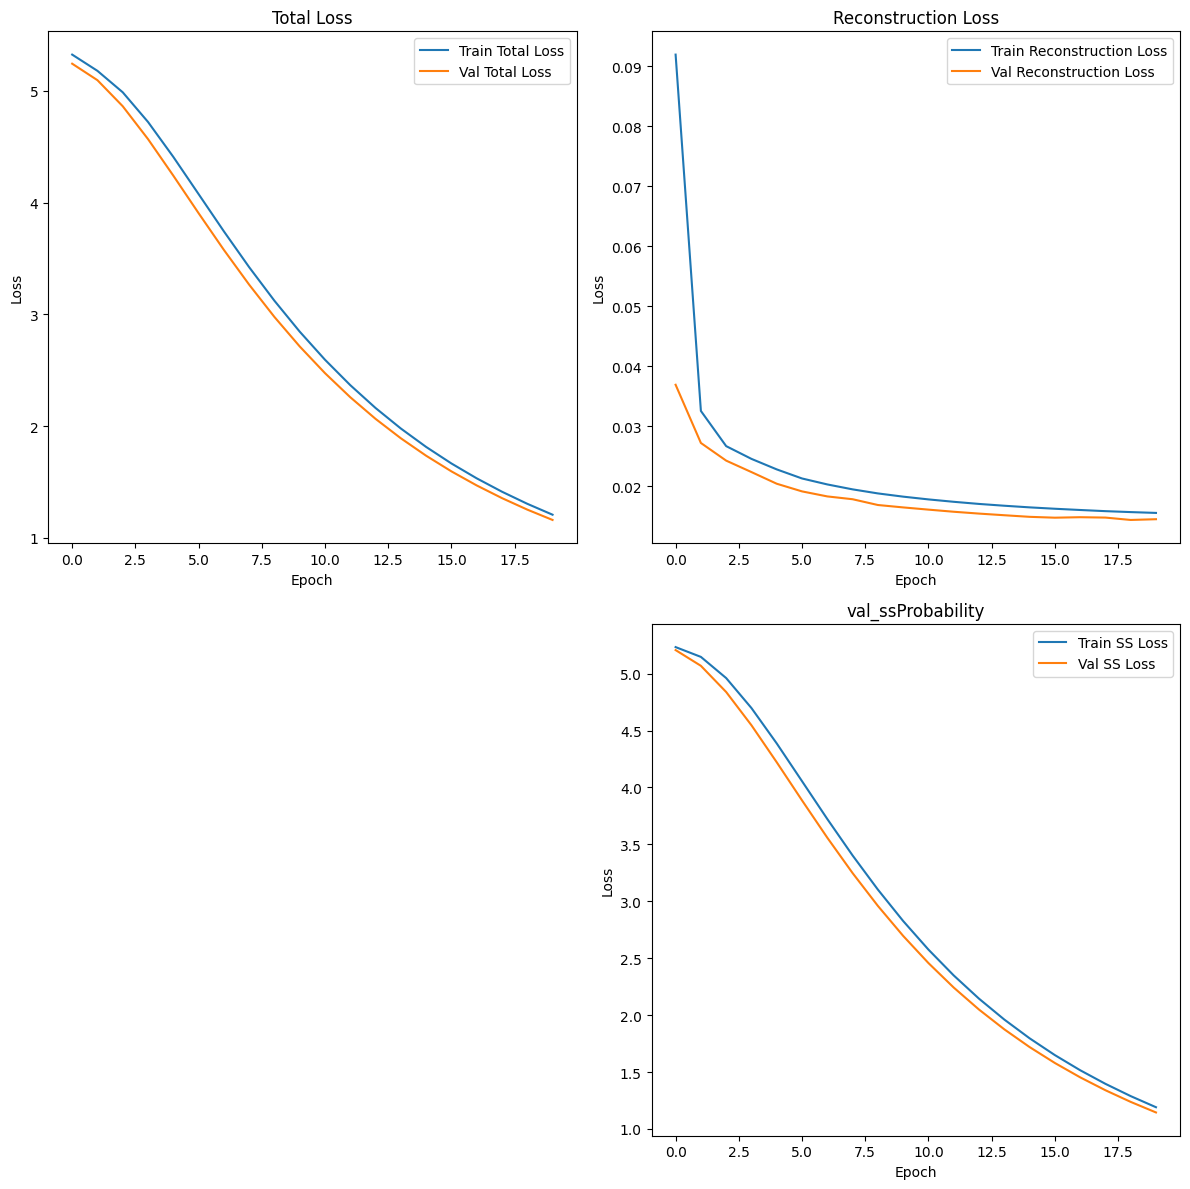

555/555 [==============================] - 1s 1ms/step


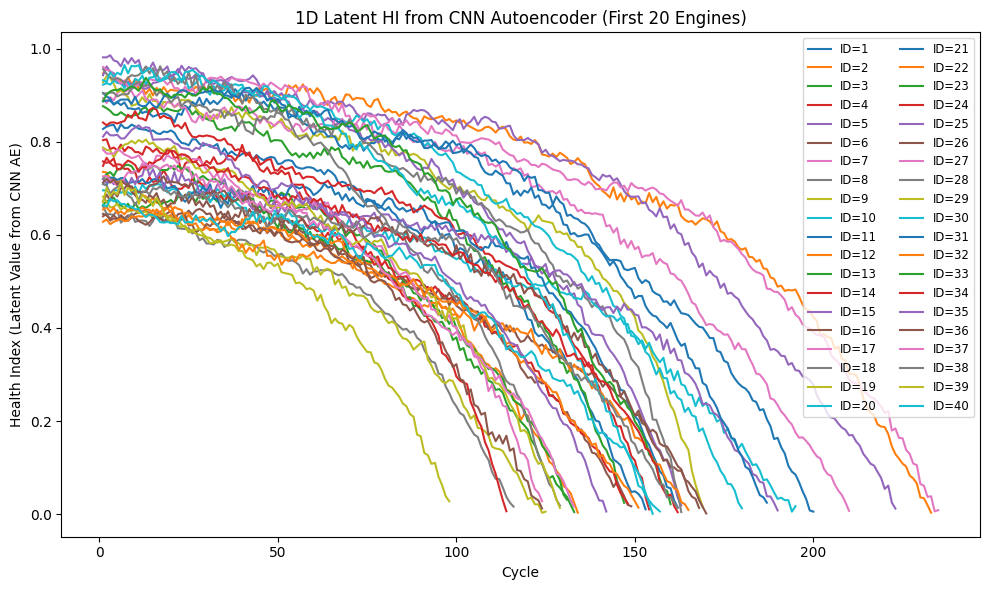

In [ ]:
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', 'utility')))
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"  
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}

from sklearn.preprocessing      import MinMaxScaler
from keras.models               import Model
from keras.layers               import Input, Conv1D, MaxPooling1D, UpSampling1D, Dense, Flatten, Reshape, ZeroPadding1D, Concatenate, Lambda, Multiply, Minimum, Maximum, LSTM, Masking
from keras.layers               import GlobalAveragePooling1D, RepeatVector
from keras.constraints          import NonNeg
from preProcessingDataTurbofan  import PreProcessData
from matpilotDraw               import MatPlot

import tensorflow           as tf
import numpy                as np
import pandas               as pd
import matplotlib.pyplot    as plt
import random
import warnings


seedNumber          = 805
hiSelectionMode     = "min"
drawTrajectories    = 300

useRUL          = False
epochTrain      = 20
prePro          = PreProcessData()
warnings.filterwarnings('ignore') 
tf.random.set_seed(seedNumber)
np.random.seed(seedNumber)
random.seed(seedNumber)

# ==============================
# This function is used to prepare 
# the data
# -----------------------------
def dataHandling(df, idName = 'engineId', sensorUsed=None, scaler = None, normalize=True):
    # -----------------------------
    # Init variables
    # sensorUsed        = ['s2','s3','s4','s7','s8','s9','s11','s12','s13','s14','s15','s17','s20','s21'] if sensorUsed is None else sensorUsed
    sensorUsed        = ['s1', 's2','s3','s4',"s5", "s6",'s7','s8','s9',"s10",'s11','s12','s13','s14','s15',"s16",'s17',"s18","s19",'s20','s21'] if sensorUsed is None else sensorUsed
    windowSize          = 30  # Fixed sequence length
    segmentedData       = []
    engineIds           = []
    beginningCycles     = []

    # -----------------------------
    # Build sliding windows from each engine
    for engId in df[idName].unique():
        dfEngine        = df[df[idName] == engId]
        engineData      = dfEngine[sensorUsed].values
        for start in range(0, len(engineData) - windowSize + 1):
            window = engineData[start : start + windowSize]
            segmentedData.append(window)
            engineIds.append(engId)
            beginningCycles.append(start + 1)

    segmentedData               = np.array(segmentedData)  # (N, 30, 14)
    N, seqLength, numFeatures   = segmentedData.shape                               # Get the shape of the data after converting to numpy array
    # -----------------------------
    # Normalize data
    if normalize:
        xFlat                       = segmentedData.reshape(N * seqLength, numFeatures)
        scaler                      = MinMaxScaler() if scaler is None else scaler
        xFlatScaled                 = scaler.fit_transform(xFlat)
        segmentedXScaled            = xFlatScaled.reshape(N, seqLength, numFeatures)
    else:
        segmentedXScaled            = segmentedData
        scaler                      = None
    return segmentedXScaled, engineIds, beginningCycles, seqLength, numFeatures, scaler


# -----------------------------
#  PREPROCESSING THE DATA
# -----------------------------
columnNames = [    "engineId",      "cycle",    "setting1", "setting2", "`setting3`",
                    "s1",           "s2",       "s3",       "s4",       "s5",       "s6",   "s7",   "s8",   "s9",   "s10",
                    "s11",          "s12",      "s13",      "s14",      "s15",      "s16",  "s17",  "s18",  "s19",  "s20",  "s21"
                ]
# sensorUsed        = ['s2','s3','s4','s7','s8','s9','s11','s12','s13','s14','s15','s17','s20','s21']
sensorUsed          = ['s1', 's2','s3','s4',"s5", "s6",'s7','s8','s9',"s10",'s11','s12','s13','s14','s15',"s16",'s17',"s18","s19",'s20','s21']
dir                 = '~/Desktop/Dropbox/1.codeData/turbofanEngines/data/'
df                  = pd.read_csv(dir + 'df_train.txt', delim_whitespace=True, header=None, names=columnNames)
df["rul"]           = df.groupby('engineId',sort=False)['cycle'].transform(lambda x: x.max() - x)         # Get RUL
df['rul']           = np.where((df.rul > 125),125,df.rul)
df['rul']           = df['rul']/125
df[sensorUsed]      = df.groupby("engineId")[sensorUsed].apply(lambda g: prePro.flip2DownPandasMultipleCol(g, g.columns))

# ------------------------------------
# Data handling before training
# ------------------------------------
xScaled, engineIds, beginningCycles, seqLength, numFeatures, scalerTrain        = dataHandling(df,sensorUsed=sensorUsed)
yRul, _, _, _, _, _                                                             = dataHandling(df, sensorUsed=['rul'],normalize=False)  # Get RUL data
yRul                                                                            = yRul[:,-1,:]  # Get last value of each sequence


# ==============================
# Sensor selection Class
# ==============================
class SensorSelection(tf.keras.layers.Layer):
    def __init__(self, inFeature = 45, numEnvs = 3):
        '''
        The input size should be (batchSize, timeStep, featureDim)        
        '''
        super(SensorSelection, self).__init__()
        self.mask_logits    = self.add_weight(  shape       =   (inFeature,),  # Each mode has different sensor probabilities
                                                initializer =   "random_normal",
                                                trainable   =   True,
                                                name        =   "sensorMask")
                                            
    def call(self,rawData):
        # ----------------------------------
        # Select the environment
        # ----------------------------------
        # env                 = tf.cast(env, tf.int32)                                # Ensure integer type for indexing, and env from 1 to three, so we need index from 0 to 2
        # env_mask_logits     = tf.gather(self.mask_logits, env, axis=0)              # (batch_size, num_sensors) each sequence (after split) will have a different env, so env should be a batch (include differnt env to access to the mask)                    
    
        probs               = tf.sigmoid(self.mask_logits)
        random_uniform      = tf.random.uniform(tf.shape(probs))
        binary_mask         = tf.cast(tf.less(0.5, probs), tf.float32)

        maskedData          = rawData * probs
        # ----------------------------------
        # Add loss function for sensor selection
            
        return maskedData, probs, binary_mask
    
    def getMask(self,):
        probs               = tf.sigmoid(self.mask_logits)   
        random_uniform      = tf.random.uniform(tf.shape(probs))
        binary_mask         = tf.cast(tf.less(0.5, probs), tf.float32) 
        return binary_mask, probs


# ==============================
# Encoder block
# ------------------------------
inputs                      = Input(shape=(seqLength, numFeatures))
Masking                     = SensorSelection(   inFeature = len(sensorUsed), numEnvs   = 1)                            
masked_input, mask_probs, _ = Masking(inputs)
x                           = Conv1D(32, 3, activation='relu', padding='same')(masked_input)
x                           = MaxPooling1D(2, padding='same')(x)
x                           = Conv1D(16, 3, activation='relu', padding='same')(x)
lastAELayer                 = MaxPooling1D(2, padding='same',name='lastAELayer')(x)
x                           = GlobalAveragePooling1D()(lastAELayer)
latent                      = Dense(1, name='latent')(x)  # HI directly here

print("The shape of last layer encoder is", lastAELayer.shape)

# ==============================
# Decoder block
# -----------------------------
x           = Dense((seqLength // 4) * 16, activation='relu')(latent)  # (7 * 16)
x           = Reshape((seqLength // 4, 16))(x)  # Shape: (7, 16)
x           = UpSampling1D(2)(x)  # Shape: (14, 16)
x           = Conv1D(32, 3, activation='relu', padding='same')(x)  # Shape: (14, 32)
x           = UpSampling1D(2)(x)  # Shape: (28, 32)
x           = ZeroPadding1D(padding=(1, 1))(x)  # Pad to get (30, 32)
decoded     = Conv1D(numFeatures, 3, activation='linear', padding='same')(x)  # Shape: (30, 14)


masked_decoded  = tf.keras.layers.Multiply(name='reconstruction')([decoded, tf.reshape(mask_probs, (1, 1, -1))])


cnnAEModel = Model(inputs, outputs=masked_decoded)
# ----------------------------------
# Calculate the losses
# ----------------------------------
recon_loss      = tf.reduce_mean(tf.abs(masked_decoded - masked_input))
sSLoss          = tf.reduce_sum(mask_probs * (1 - mask_probs))

cnnAEModel.add_loss(sSLoss)
cnnAEModel.add_metric(sSLoss, name="ssProbability", aggregation="mean")

cnnAEModel.add_loss(recon_loss)
cnnAEModel.add_metric(recon_loss, name="recon_loss", aggregation="mean")
cnnAEModel.compile(optimizer='adam')

# print(cnnAEModel.output_names)  # ['reconstruction']
# print(cnnAEModel.metrics_names) # ['loss', 'mae', 'ssProbability']


history = cnnAEModel.fit(xScaled, epochs=epochTrain, batch_size=128, validation_split=0.1, verbose=1)


# ==========================================
#               PLOT
# ------------------------------------------
print(history.history.keys())
plt.figure(figsize=(12, 12))

plt.subplot(2, 2, 1)
plt.plot(history.history['loss'], label='Train Total Loss')
plt.plot(history.history['val_loss'], label='Val Total Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Total Loss')
plt.legend()

# --- Plot reconstruction loss ---
plt.subplot(2, 2, 2)
plt.plot(history.history['recon_loss'], label='Train Reconstruction Loss')
plt.plot(history.history['val_recon_loss'], label='Val Reconstruction Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Reconstruction Loss')
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(history.history['ssProbability'], label='Train SS Loss')
plt.plot(history.history['val_ssProbability'], label='Val SS Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('val_ssProbability')
plt.legend()

plt.tight_layout()
plt.show()


# ==============================
# Extract latent HI values
# ------------------------------
encoder = Model(    inputs  =  cnnAEModel.input,
                    outputs = [cnnAEModel.get_layer('lastAELayer').output, cnnAEModel.get_layer('latent').output],  name="encoder_submodel")
                                                    
_, rawHIValues      = encoder.predict(xScaled)
hiValues            = rawHIValues.flatten()                                                     # Flatten to 1D array
dfHI                = pd.DataFrame({'id'    : engineIds,
                                    'cycle' : beginningCycles,
                                    'HI'    : -hiValues})                                        # Build dataframe for plotting

hiThreshold         = max(dfHI.groupby('id')['HI'].min())
upperHI             = max(dfHI.groupby('id')['HI'].max())
dfHI                = dfHI[dfHI['HI'] > hiThreshold]                                          # Filter out engines with HI > threshold

dfHI["HI"]          = (dfHI["HI"] - hiThreshold) / (upperHI - hiThreshold)           # Normalize HI

# print("The min HI value is", hiThreshold)
# ==============================                
# Plot first 20 engines
# ------------------------------
plt.figure(figsize=(10, 6))
for eng_id in dfHI['id'].unique()[:40]:
    df_eng = dfHI[dfHI['id'] == eng_id]
    plt.plot(df_eng['cycle'], df_eng['HI'], label=f'ID={eng_id}')
plt.xlabel("Cycle")
plt.ylabel("Health Index (Latent Value from CNN AE)")
plt.title("1D Latent HI from CNN Autoencoder (First 20 Engines)")
plt.legend(ncol=2, fontsize='small')
plt.tight_layout()
plt.show()



In [ ]:
df_test  = pd.read_csv(dir + 'df_test.txt',  sep='\s+', names=columnNames, header=None)
df_true  = pd.read_csv(dir + 'df_true.txt',                 names=['RUL'], header=None)
# —————————————————————————————
# ASSUMES YOU ALREADY HAVE:
#   xScaled, engineIds, beginningCycles, yRul
#   encoder  (maps xScaled windows → 1-dim HI)
#   df_test, df_true  (loaded earlier)
# —————————————————————————————

# 1) Get HI for every training window
# rawHI is shape (N_windows, 1)
_, rawHI = encoder.predict(xScaled, batch_size=128)
hi_train = rawHI.flatten()          # shape (N,)

# yRul was built earlier via dataHandling(df_train,sensorUsed=['rul'])
# shape (N,) and already in [0,1] (since you clipped at 125 and divided)
# ensure shapes align:
# assert hi_train.shape == yRul.shape

# 2) Build & train the regressor
regressor = Sequential([
    Dense(64, activation='relu', input_shape=(1,)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='linear'),
], name='HI_to_RUL')

regressor.compile(optimizer='adam', loss='mse')

regressor.fit(
    hi_train.reshape(-1,1),
    yRul,
    epochs=50,
    batch_size=16,
    validation_split=0.1,
    verbose=2
)

# 3) Prepare test windows exactly as for train
#    (flip2Down, sliding windows of length=seqLength, MinMaxScaler from train)
# xTest, testIds, testStarts, _, _, _ = dataHandling(
#     df_test,
#     sensorUsed=sensorUsed,
#     scaler=prePro,        # or the scaler you used above
#     normalize=True
# )



# 4) Extract each test window’s HI
_, rawHI_test = encoder.predict(xTest, batch_size=128)
hi_test_all = rawHI_test.flatten()

# 5) For each engine, pick *only* its last window’s HI
last_hi = {}
for hi, eid, start in zip(hi_test_all, testIds, testStarts):
    # newest window has largest 'start' index
    if (eid not in last_hi) or (start > last_hi[eid][0]):
        last_hi[eid] = (start, hi)
hi_test = np.array([v[1] for k,v in sorted(last_hi.items())])

# 6) Predict & rescale back to cycles
y_pred_norm = regressor.predict(hi_test.reshape(-1,1)).flatten()
y_pred = y_pred_norm * 125.0              # undo your earlier /125
y_true = df_true['RUL'].values            # true cycles remaining

# 7) Compute RMSE
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
print(f"Stage 2 RUL Test RMSE = {rmse:.2f} cycles")


139/139 [==============================] - 0s 2ms/step
Epoch 1/50
998/998 - 2s - loss: 0.0472 - val_loss: 0.0289 - 2s/epoch - 2ms/step
Epoch 2/50
998/998 - 2s - loss: 0.0266 - val_loss: 0.0283 - 2s/epoch - 2ms/step
Epoch 3/50
998/998 - 2s - loss: 0.0258 - val_loss: 0.0346 - 2s/epoch - 2ms/step
Epoch 4/50
998/998 - 2s - loss: 0.0249 - val_loss: 0.0296 - 2s/epoch - 2ms/step
Epoch 5/50
998/998 - 2s - loss: 0.0245 - val_loss: 0.0329 - 2s/epoch - 2ms/step
Epoch 6/50
998/998 - 2s - loss: 0.0240 - val_loss: 0.0347 - 2s/epoch - 2ms/step
Epoch 7/50
998/998 - 2s - loss: 0.0236 - val_loss: 0.0534 - 2s/epoch - 2ms/step
Epoch 8/50
998/998 - 2s - loss: 0.0234 - val_loss: 0.0490 - 2s/epoch - 2ms/step
Epoch 9/50
998/998 - 2s - loss: 0.0230 - val_loss: 0.0455 - 2s/epoch - 2ms/step
Epoch 10/50
998/998 - 2s - loss: 0.0230 - val_loss: 0.0663 - 2s/epoch - 2ms/step
Epoch 11/50
998/998 - 2s - loss: 0.0228 - val_loss: 0.0537 - 2s/epoch - 2ms/step
Epoch 12/50
998/998 - 2s - loss: 0.0226 - val_loss: 0.0578 - 2s

Model: "encoder_submodel"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_14 (InputLayer)       [(None, 30, 21)]          0         
                                                                 
 sensor_selection_4 (SensorS  ((None, 30, 21),         21        
 election)                    (21,),                             
                              (21,))                             
                                                                 
 conv1d_16 (Conv1D)          (None, 30, 32)            2048      
                                                                 
 max_pooling1d_4 (MaxPooling  (None, 15, 32)           0         
 1D)                                                             
                                                                 
 conv1d_17 (Conv1D)          (None, 15, 16)            1552      
                                                  

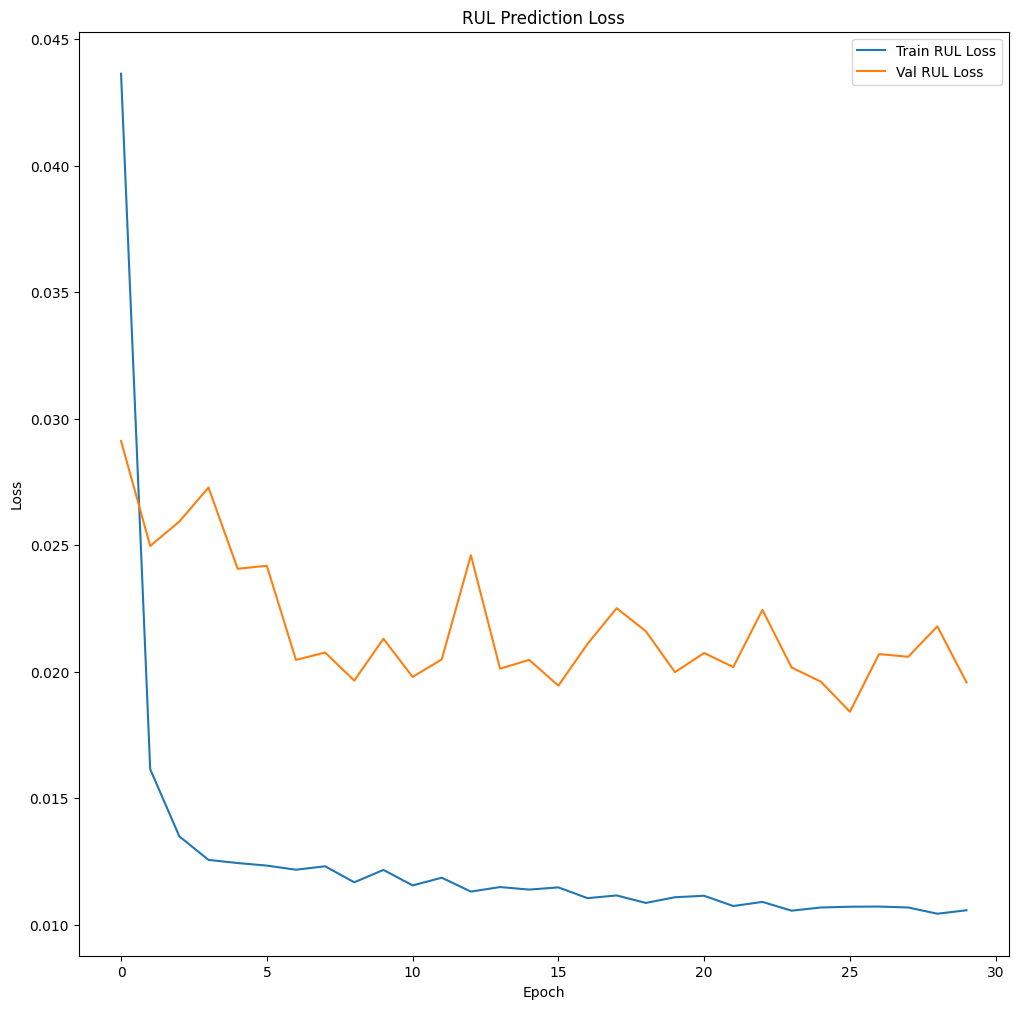

In [25]:
epochTrain      = 30

# for layer in encoder.layers:
#     layer.trainable = False

print(encoder.summary())

input1               = Input(shape=(seqLength, numFeatures))
inputRUL1, latent   =  encoder(input1)

curHI           = (-latent - hiThreshold) / (upperHI - hiThreshold)
# rulLayer1       = LSTM(32, return_sequences=True)(inputRUL1)
# rulLayer2       = LSTM(16, return_sequences=True)(inputRUL1)
# rulLayer3       = LSTM(4, return_sequences=False)(rulLayer2)
# rulLayer4       = Concatenate(axis=-1)([rulLayer3, curHI])

# rul             = Dense(1, activation='linear', name="RUL_Output")(rulLayer4)

# --------------------------------
# RUL with Dense

flat   = Flatten(name="rul_flatten")(inputRUL1)              # (batch, seqLen/4 * 16)

d1     = Dense(32, activation="relu", name="rul_dense1")(flat)
d2     = Dense(16, activation="relu", name="rul_dense2")(d1)
d3     = Dense(4,  activation="relu", name="rul_dense3")(d2)

# 4) merge with curHI and predict
merged = Concatenate(name="rul_concat")([d3, curHI])        # (batch, 5)
rul    = Dense(1, activation="linear", name="RUL_Output")(merged)



# ==============================
# Use RUL as label
# ------------------------------    
compRulModel    = Model(inputs=[input1], outputs=[rul], name="componentRulModel")
compRulModel.summary()


compRulModel.compile(   optimizer    = 'adam', 
                        loss         = { 'RUL_Output': 'mse'},
                        loss_weights = { 'RUL_Output': 1})  # adjust weights as needed:

history         = compRulModel.fit(xScaled, yRul,epochs=epochTrain, batch_size=128, validation_split=0.1, verbose=1)


print(history.history.keys())
plt.figure(figsize=(12, 12))

    # --- Plot RUL prediction loss ---
# plt.subplot(2, 2, 3)
plt.plot(history.history['loss'], label='Train RUL Loss')
plt.plot(history.history['val_loss'], label='Val RUL Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('RUL Prediction Loss')
plt.legend()

In [3]:
# plt.figure(figsize=(10, 6))
# for eng_id in dfHI['id'].unique()[:40]:
#     df_eng = dfHI[dfHI['id'] == eng_id]
#     plt.plot(df_eng['cycle'], df_eng['rul'], label=f'ID={eng_id}')
# plt.xlabel("Cycle")
# plt.ylabel("Remaining Useful Life (RUL)")
# plt.title("RUL from CNN Autoencoder (First 40 Engines)")
# plt.legend(ncol=2, fontsize='small')
# plt.tight_layout()
plt.show()

#### Sensor selection

In [4]:
from prettytable    import PrettyTable

binaryMask, mask_probs = Masking.getMask()
print(binaryMask.shape, mask_probs.shape)

ssTable                 = PrettyTable()
ssTable.field_names     = ["No","sensorName","probability", "binary"]
print(f"The number of selected sensor is {sum(binaryMask)}")
for idx,idxSS in enumerate(sensorUsed):
    ssTable.add_row([idx,idxSS,mask_probs[idx].numpy(),binaryMask[idx].numpy()])

print(ssTable)


(21,) (21,)
The number of selected sensor is 4.0
+----+------------+-------------+--------+
| No | sensorName | probability | binary |
+----+------------+-------------+--------+
| 0  |     s1     | 0.027611632 |  0.0   |
| 1  |     s2     |  0.02766442 |  0.0   |
| 2  |     s3     | 0.027704898 |  0.0   |
| 3  |     s4     | 0.027558172 |  0.0   |
| 4  |     s5     | 0.027915284 |  0.0   |
| 5  |     s6     | 0.027839672 |  0.0   |
| 6  |     s7     |  0.97249967 |  1.0   |
| 7  |     s8     | 0.027619043 |  0.0   |
| 8  |     s9     | 0.027904816 |  0.0   |
| 9  |    s10     | 0.027587112 |  0.0   |
| 10 |    s11     |  0.02756386 |  0.0   |
| 11 |    s12     |  0.02779769 |  0.0   |
| 12 |    s13     | 0.027734559 |  0.0   |
| 13 |    s14     | 0.027766377 |  0.0   |
| 14 |    s15     |  0.97248423 |  1.0   |
| 15 |    s16     |  0.02760896 |  0.0   |
| 16 |    s17     |  0.97248465 |  1.0   |
| 17 |    s18     |  0.02762133 |  0.0   |
| 18 |    s19     |  0.02766895 |  0.0   |
| 19 

#### Evaluation metrics

##### RMSE

In [26]:
dfTest                  = pd.read_csv('~/Desktop/Dropbox/1.codeData/turbofanEngines/data/df_test.txt', delim_whitespace=True, header=None, names=columnNames)
dfRul                   = pd.read_csv('~/Desktop/Dropbox/1.codeData/turbofanEngines/data/df_true.txt', delim_whitespace=True, header=None, names=['rul'])

dfRul                   = np.where((dfRul > 125),125.0,dfRul)
dfRul                   = dfRul.flatten()


dfTest[sensorUsed]      = dfTest.groupby("engineId")[sensorUsed].apply(lambda g: prePro.flip2DownPandasMultipleCol(g, g.columns))

xTestScaled, engineTestIds, beginningTestCycles, seqLength, numFeatures, _  = dataHandling(dfTest)
# yTestRul, _, _, _, _, scalerRUL                                     = dataHandling(dfTest, sensorUsed=['rul'])  # Get RUL data
# yTestRulWindowOrginal, _, _, _, _, _                                = dataHandling(dfTest, sensorUsed=['rul'],normalize=False)  # Get RUL data
# yTestRul                                                            = yTestRul[:,-1,:]  # Get last value of each sequence

rulTestPredictions    = compRulModel.predict(xTestScaled)  # Get predictions

rulTestPredictions      = scalerRUL.inverse_transform(rulTestPredictions)

dfRUL                = pd.DataFrame({'id'    : engineTestIds,
                                    'rul'   : rulTestPredictions.flatten(),
                                    })   

predictedRUL = dfRUL.groupby("id")['rul'].last()
print(predictedRUL)
# print(predictedRUL.shape)
print(predictedRUL.shape)
print(dfRul.shape)

rmse    = np.sqrt(np.mean((predictedRUL - dfRul) ** 2))

print(rmse)




319/319 [==============================] - 1s 1ms/step
id
1      61.107021
2      54.691814
3      30.427572
4      45.062614
5      49.972572
         ...    
96     59.773033
97     48.072876
98     33.197094
99     60.208595
100    11.528222
Name: rul, Length: 100, dtype: float32
(100,)
(100,)
45.00168318078961


In [6]:

min_rul = scalerRUL.data_min_[0]
max_rul = scalerRUL.data_max_[0]

print(f"Original RUL range: {min_rul} to {max_rul}")


rulPredictionsOrginal   = scalerRUL.inverse_transform(rulTestPredictions)
rmse                    = np.sqrt(np.mean((rulPredictionsOrginal - yTestRulWindowOrginal[:,-1,:]) ** 2))
print("RMSE of RUL predictions:", rmse)


Original RUL range: 0.0 to 125.0


NameError: name 'yTestRulWindowOrginal' is not defined

##### M, T

In [ ]:
_, rawHIValues          = encoder.predict(xTestScaled)
hiTestValues            = rawHIValues.flatten()                # Flatten to 1D array
print("--------------------------------------")
print(hiTestValues.shape, len(engineTestIds))


dfHITest                = pd.DataFrame({'id'    : engineTestIds,
                                    'rul'   : rulPredictionsOrginal.flatten(),
                                    'cycle' : beginningTestCycles,
                                    'HI'    : hiTestValues})                                        # Build dataframe for plotting
rawHI               = dfHITest.copy()  # Keep raw HI values for later use

# print(dfHITest.head())

# savedHI = dfHITest[dfHITest['id'] == 1].reset_index(drop=True)
# savedHI.to_csv("HI1.csv", index=False)

hiThreshold         = max(dfHITest.groupby('id')['HI'].min())
upperHI             = max(dfHITest.groupby('id')['HI'].max())
dfHITest            = dfHITest[dfHITest['HI'] > hiThreshold]                     # Filter out engines with HI > threshold

dfHITest["HI"]      = (dfHITest["HI"] - hiThreshold) / (upperHI - hiThreshold)           # Normalize HI

In [ ]:
# ==============================
#           MONOTONICITY
# ==============================
def proportion_based_monotonicity(hi_series, segment_size=12):
    """
    Calculate proportion-based monotonicity using segments.

    Parameters:
        hi_series (pd.Series)   : Health indicator series (e.g., HI values over time).
        segment_size (int)      : Size of each segment.

    Returns:
        float                   : Proportion-based monotonicity (range 0 to 1).
    """
    hi_series = hi_series.dropna()  # Remove NaN values
    
    if len(hi_series) < segment_size * 2:
        raise ValueError("Not enough data to calculate monotonicity with the specified segment size.")

    # ----------------------------------
    # Step 1: Divide the data into segments
    # and calculate the mean of each segment
    # -----------------------------------
    num_segments    = len(hi_series) // segment_size
    aggregated      = [hi_series.iloc[i * segment_size:(i + 1) * segment_size].mean() for i in range(num_segments)]


    # ----------------------------------
    # Step 2: Calculate the proportion
    # of consistent steps
    # ----------------------------------
    diffs           = pd.Series(aggregated).diff().dropna()  # Calculate differences between segments
    positive_steps  = (diffs > 0).sum()
    negative_steps  = (diffs < 0).sum()

    # ----------------------------------
    # Step 3: Calculate monotonicity as
    # the proportion of consistent steps
    # ----------------------------------
    total_steps = len(diffs)
    monotonicity = abs((positive_steps - negative_steps) / total_steps)  # Normalize to 0-1
    return monotonicity

def calculate_monotonicity(hi_series: pd.Series) -> float:
    """
    Calculate a single‐trajectory monotonicity:
        Mon = |#(∆HI > 0) − # (∆HI < 0)|  /  (n − 1)

    Parameters:
        hi_series (pd.Series): A single HI trajectory (ordered by time).

    Returns:
        float: Monotonicity in [0, 1].
    """
    hi_series = hi_series.dropna()
    n = len(hi_series)
    if n < 2:
        return 0.0

    # Compute first differences
    diffs = hi_series.diff().dropna()
    pos_steps = (diffs > 0).sum()
    neg_steps = (diffs < 0).sum()

    return abs(pos_steps - neg_steps) / (n - 1)


# ==============================
#           ROBUSTNESS
# ==============================
def calculate_robustness_polyfit(hi_series, degree=25):
    """
    Calculate robustness using polynomial fitting for trend estimation.

    Parameters:
        hi_series (pd.Series)   : Health indicator series (e.g., HI values over time).
        degree (int)            : Degree of the polynomial for trend fitting.

    Returns:
        float                   : Robustness score (range 0 to 1).
    """
    hi_series   = hi_series.dropna()  # Remove NaN values
    n           = len(hi_series)
    if n < degree + 1:
        return 0.0  # Not enough data to fit the polynomial

    # --------------------------------
    # Step 1: Fit a polynomial trend
    # --------------------------------
    x               = np.arange(n)
    y               = hi_series.values
    poly_coeffs     = np.polyfit(x, y, degree)  # Fit polynomial
    poly_trend      = np.polyval(poly_coeffs, x)  # Evaluate polynomial trend

    # --------------------------------
    # Step 2: Calculate deviations and 
    # normalize by standard deviation
    # --------------------------------
    deviations      = abs(hi_series - poly_trend)
    std_dev         = hi_series.std()
    if std_dev == 0:
        return 1.0  # Perfect stability, no variance

    normalized_deviations = deviations / std_dev

    # --------------------------------
    # Step 3: Compute robustness
    # --------------------------------
    robustness      = np.exp(-normalized_deviations.mean())
    return robustness

def chunked_robustness(hi_series, chunk_size =10):
    hi_series = hi_series.dropna().reset_index(drop=True)
    n = len(hi_series)
    if n < chunk_size * 2:
        return 0.0

    num_chunks = n // chunk_size
    chunk_means = [hi_series[i * chunk_size:(i + 1) * chunk_size].mean()
                   for i in range(num_chunks)]
    
    chunk_series = pd.Series(chunk_means)
    std = chunk_series.std()
    if std <= 1e-7:
        return 1.0  # perfect stability
    
    norm_diff = np.abs((chunk_series - chunk_series.mean()) / std)
    return np.exp(-norm_diff.mean())



def robustness_single_hi(hi_series: pd.Series) -> float:
    """
    Calculate robustness for a single health indicator series.

    Parameters:
        hi_series (pd.Series): A single health indicator trajectory.

    Returns:
        float: Robustness value in [0, 1].
    """

    hi_series = hi_series.dropna()
    if len(hi_series) == 0:
        raise ValueError("Input series is empty after dropping NaN values.")

    std = hi_series.std()
    if std <= 1e-7:
        raise ValueError("Standard deviation is too small, indicating no variability in the series.")

    mean_hi             = hi_series.mean()
    normalized_diff     = np.abs((hi_series - mean_hi) / std)
    rob                 = np.exp(-normalized_diff.mean())
    return rob


# ==============================
#           TRENDABILITY
# ==============================
def calculate_trendability1(hi_series, time = None, time_step=0.5):
    """
    Calculate trendability using covariance between time and HI.

    Parameters:
        hi_series (pd.Series): Health indicator series (e.g., HI values over time).
        time_step (float): Step size for generating time values.

    Returns:
        float: Trendability score.
    """
    hi_series   = hi_series.dropna()  # Remove NaN values
    n           = len(hi_series)
    if n < 2:
        raise ValueError("Not enough data to calculate trendability.")

    
    time            = np.arange(0, n * time_step, time_step) 
    covariance      = np.cov(time, hi_series)[0, 1]                     # Step 2: Calculate covariance
    trendability    = abs(covariance)                                   # Step 3: Return the absolute value of covariance
    
    return trendability

def calculate_trendability(hi_series, time=None, time_step=0.5):
    """
    Calculate trendability using the absolute Pearson correlation between time and HI,
    based on the interpretation in the referenced paper.

    Parameters:
        hi_series (pd.Series): Health indicator series (e.g., HI values over time).
        time (array-like, optional): Time values aligned with the series.
        time_step (float): Used to generate uniform time if 'time' is not provided.

    Returns:
        float: Trendability score in [0, 1].
    """
    hi_series = hi_series.dropna()
    n = len(hi_series)
    if n < 2:
        raise ValueError("Not enough data to calculate trendability.")

    time = np.arange(n) * time_step if time is None else np.array(time)
    if len(time) != n:
        raise ValueError("Time and HI series must be of the same length.")

    correlation = np.corrcoef(time, hi_series)[0, 1]
    return abs(correlation)


In [ ]:
# ---------------------------------------
# Compute robustness, trendability, 
# and monotonicity for a single HI trajectory.
# ---------------------------------------
def compute_hi_metrics_for_id(df: pd.DataFrame, hiCol = "HI") -> dict:
    """
    Parameters:
        df (pd.DataFrame): DataFrame with 'cycle' and 'HI' columns for one engine ID.

    Returns:
        dict: Dictionary with metrics.
    """
    # hi_series = df.sort_values("cycle")["HI"]
    hi_series = df[hiCol]
    try:
        robustness = chunked_robustness(hi_series)
    except ValueError:
        robustness = np.nan

    try:
        trendability = calculate_trendability(hi_series, time=df["cycle"])
    except ValueError:
        trendability = np.nan

    try:
        monotonicity = proportion_based_monotonicity(hi_series)
        # print(f"Monotonicity for ID {df['id'].iloc[0]}: {monotonicity}")
    except ValueError:
        monotonicity = np.nan

    return {
        "robustness": robustness,
        "trendability": trendability,
        "monotonicity": monotonicity
    }

# ---------------------------------------
# Compute the average robustness, trendability, 
# and monotonicity over all HI trajectories.
# ---------------------------------------
def compute_average_hi_metrics(dfHI: pd.DataFrame, hiCol = "HI"):
    """
    Parameters:
        dfHI (pd.DataFrame): DataFrame with columns 'id', 'cycle', and 'HI'.

    Returns:
        dict: Dictionary with average metric values.
    """
    grouped         = dfHI.groupby("id")
    metrics_list    = [compute_hi_metrics_for_id(group, hiCol) for _, group in grouped]

    # Convert to DataFrame for easy averaging and NaN handling
    metrics_df      = pd.DataFrame(metrics_list)

    return {
        "avg_robustness": metrics_df["robustness"].mean(),
        "avg_trendability": metrics_df["trendability"].mean(),
        "avg_monotonicity": metrics_df["monotonicity"].mean()
    }


In [ ]:
compMetrics = compute_average_hi_metrics(dfHI)
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

### 2. FOR SYSTEM

#### Data for system model

In [ ]:
# ========================================
# This function is used to resize the data
# to have the same length between 
# different engines
# ----------------------------------------
def resize_group(g, targetLen, fill_value=0, id_col='trajectoryID', cycle_col='cycle'):
    currentLen  = len(g)
    pad_size    = targetLen - currentLen

    if pad_size == 0:
        return g
    elif pad_size < 0:
        return g.iloc[:targetLen].reset_index(drop=True)

    # Padding case: pad_size > 0
    lastCycle       = g[cycle_col].iloc[-1] if cycle_col in g.columns else currentLen - 1
    pad_df          = pd.DataFrame(fill_value, index=range(pad_size), columns=g.columns)
    pad_df[id_col]  = g[id_col].iloc[0]
    
    if cycle_col in g.columns:
        pad_df[cycle_col] = range(lastCycle + 1, lastCycle + pad_size + 1)

    return pd.concat([g, pad_df], ignore_index=True)


def createSystemData(inData, numberOfTrajectories=300, mode = "max", seed = 2):
    np.random.seed(seed)

    rawData         = inData
    # --------------------------
    # Group the data into ID and
    # initiate the values
    # --------------------------
    grouped_data    = {k: v for k, v in rawData.groupby("engineId")}                                                      # Pre-group `rawData` by 'id' for O(1) lookup
    # createdData     = {}                                                                                                # Initialize dictionary for cases
    # --------------------------
    # Create system data
    # --------------------------
    selected_ids    = np.array([np.random.choice(np.arange(1, 101), size=3, replace=False) for _ in range(numberOfTrajectories)])     # Generate 400 sets of 3 unique trajectory IDs per iteration
    
    comp1_df        = pd.concat([grouped_data[i].assign(trajectoryID=trajectID + 1) for trajectID, i in enumerate(selected_ids[:, 0])], ignore_index=True) 
    comp2_df        = pd.concat([grouped_data[i].assign(trajectoryID=trajectID + 1) for trajectID, i in enumerate(selected_ids[:, 1])], ignore_index=True) 
    comp3_df        = pd.concat([grouped_data[i].assign(trajectoryID=trajectID + 1) for trajectID, i in enumerate(selected_ids[:, 2])], ignore_index=True)                    # Fetch data from grouped dictionary (guaranteed unique per iteration)
    
    lenEachIDComp1  = comp1_df.groupby("trajectoryID").size()
    lenEachIDComp2  = comp2_df.groupby("trajectoryID").size()
    lenEachIDComp3  = comp3_df.groupby("trajectoryID").size()
    lengths         = pd.concat([lenEachIDComp1, lenEachIDComp2, lenEachIDComp3], axis=1)
    lengths.columns = ['len1', 'len2', 'len3']

    dfRul           = pd.DataFrame(columns=["rul", "trajectoryID"])  
    if mode == 'min':
        minLen       = lengths.min(axis=1)
        comp1Handled = comp1_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp2Handled = comp2_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp3Handled = comp3_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        dfRul["rul"] = pd.concat([comp1Handled["rul"], comp2Handled["rul"], comp3Handled["rul"]], axis=1).min(axis=1)
    
    elif mode == 'max':
        minLen       = lengths.min(axis=1)
        comp1Handled = comp1_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp2Handled = comp2_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp3Handled = comp3_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        dfRul["rul"] = pd.concat([comp1Handled["rul"], comp2Handled["rul"], comp3Handled["rul"]], axis=1).max(axis=1)

    else:
        minLen          = lengths.min(axis=1)
        comp1Handled    = comp1_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp2Handled    = comp2_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp3Handled    = comp3_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        dfRul["rul"]    = comp1_df["rul"].combine(comp2_df["rul"], max).combine(comp3_df["rul"], min)
        # dfRul.to_excel('output.xlsx', index=False)  # index=False removes the row numbers
    dfRul["comp1"]  = comp1Handled["rul"]
    dfRul["comp2"]  = comp2Handled["rul"]                                                                # Initialize RUL dataframe
    dfRul["comp3"]  = comp3Handled["rul"]
    
    dfRul["trajectoryID"] = comp1Handled["trajectoryID"]      # Add trajectoryID to RUL data
 
    return comp1Handled, comp2Handled, comp3Handled, dfRul, selected_ids

def createRULLabel(inData, mode = "max"):
    if mode == 'min':
        sysRUL = inData.min(axis =2)
    elif mode == 'max':
        sysRUL = inData.max(axis =2)
    else:
        col1 = inData[:,:, 0]
        col2 = inData[:,:, 1]
        col3 = inData[:,:, 2]
        intermediate_max = np.maximum(col1, col2)
        sysRUL = np.minimum(intermediate_max, col3)

    # print(sysRUL.shape, sysRUL[:,-1,:].shape)
    return sysRUL[:,-1]

# ============================
# This function is used to
# get the alightID at the alight 
# position of HI and RUL
# ============================
def getAlightID(rawHIValues,yRul, eng_id, selected_ids):
    rawHIValues = rawHIValues.flatten()     # Flatten to 1D array
    yRul        = yRul.flatten()            # Flatten to 1D array
    matchedID   = []

    # --------------------------------
    # For over the the selectedIds,
    # Then make a comparison of each
    # row of selectedIds, if it follow
    # the order of RUL, get the row of
    # selectedIds
    # --------------------------------
    for orderIdx,idxSelection in enumerate(selected_ids):
        idx1        = idxSelection[0]
        idx2        = idxSelection[1]
        idx3        = idxSelection[2]
        # print(idx1, idx2, idx3)
        # print("---------------------",orderIdx)
        curHI1      = rawHIValues[eng_id == idx1][0]
        curHI2      = rawHIValues[eng_id == idx2][0]
        curHI3      = rawHIValues[eng_id == idx3][0]

        # print(curHI1, curHI2, curHI3)
        
        rul1        = yRul[eng_id == idx1][0]
        rul2        = yRul[eng_id == idx2][0]
        rul3        = yRul[eng_id == idx3][0]

        # print(rul1, rul2, rul3 )
        # -----------------------------
        # Get the order from selected IDs
        # if HI and RUL are in the same order
        # -----------------------------
        if np.argsort([curHI1,curHI2,curHI3]).tolist() == np.argsort([rul1,rul2,rul3]).tolist():  # → True
            matchedID.append(orderIdx+1)
    
    return matchedID
        


#### System Model

In [ ]:
systemSeed  = 1
sysEpoch    = 30           
tf.random.set_seed(systemSeed)
np.random.seed(systemSeed)
random.seed(systemSeed)


comp1, comp2, comp3, dfRul, selected_ids            = createSystemData(df, numberOfTrajectories=300, mode=hiSelectionMode, seed = systemSeed)  # Create system data

xScaled1, engineIds1, beginningCycles1, _, _, _     = dataHandling(comp1,   idName='trajectoryID')
xScaled2, engineIds2, beginningCycles2, _, _, _     = dataHandling(comp2,   idName='trajectoryID')
xScaled3, engineIds3, beginningCycles3, _, _, _     = dataHandling(comp3,   idName='trajectoryID')
allRUL, _, _, _, _, sysRulScaler                    = dataHandling(dfRul,   idName='trajectoryID', sensorUsed=['comp1', 'comp2', 'comp3'])  # Get RUL data
sysRUL                                              = createRULLabel(allRUL, mode = hiSelectionMode)
# print(sysRUL.shape)

# ============================
# Freeze the encoder
# ----------------------------
print("==========================")
print("           Encoder          ")
print("==========================")
encoder.summary()
for layer in encoder.layers:
    layer.trainable = False

# ============================
# The loss function for HI selection
# ----------------------------
def selection_entropy_loss(y_true, y_pred):
    """
    y_pred: hiMatrixOutput -> shape (None, 3)
    We ignore y_true because we don't have a label for it.
    This returns the negative sum(p * log p).
    """
    # Add a small constant (1e-10) inside the log to avoid log(0).
    # The shape of this expression is (batch_size,).
    neg_entropy = -tf.reduce_sum(y_pred * tf.math.log(y_pred + 1e-10), axis=-1)
    return neg_entropy



# ===============================
# MODEL
# ===============================
input1              = Input(shape=(seqLength, numFeatures))
input2              = Input(shape=(seqLength, numFeatures))
input3              = Input(shape=(seqLength, numFeatures))

inputRUL1, HI1 = encoder(input1)
inputRUL2, HI2 = encoder(input2)
inputRUL3, HI3 = encoder(input3)


flatInRUL1          = Flatten()(inputRUL1)  # Shape: (32, 40)
flatInRUL2          = Flatten()(inputRUL2)  # Shape: (32, 40)
flatInRUL3          = Flatten()(inputRUL3)  # Shape: (32, 40)
hiSelectionInput    = Concatenate(axis=-1)([flatInRUL1, flatInRUL2, flatInRUL3])

# ------------------------------
# Create the HI selection matrix
# ------------------------------
x                   = Dense(24, activation="relu")(hiSelectionInput)
x                   = Dense(16, activation="relu")(x)
selection_logits    = Dense(3, activation=None, name="Selection_Logits")(x)
hiMatrixOutput      = Lambda(lambda x: tf.nn.softmax(x / 1), name="Selection_Output")(selection_logits)  # Softmax with τ=0.1 for sharper selection

# ------------------------------
# Create min, max and linear HI
# ------------------------------
minSysHi        = Minimum()([HI1, HI2, HI3])
maxSysHi        = Maximum()([HI1, HI2, HI3])
linearSysHi     = Minimum()([Maximum()([HI1, HI2]), HI3])


sysConcatenatedHi   = tf.keras.layers.Concatenate(axis=-1, name="sysConcatenatedHi")([minSysHi, maxSysHi, linearSysHi])
selected_HI         = Multiply(name="Selected_HI")([hiMatrixOutput, sysConcatenatedHi])
sysHi               = Lambda(lambda x: tf.reduce_sum(x, axis=-1, keepdims=True), name="Final_HI")(selected_HI)            # Final HI (ensuring only one HI contributes to output)

# ------------------------------
# RUL
# ------------------------------
concatenatedRULInput    = Concatenate(axis=-1)([inputRUL1, inputRUL2, inputRUL3])
rulLayer1               = LSTM(32, return_sequences=True)(concatenatedRULInput)
rulLayer2               = LSTM(16, return_sequences=True)(rulLayer1)
rulLayer3               = LSTM(3, return_sequences=False)(rulLayer2)
rulLayer4               = Concatenate(axis=-1)([rulLayer3, sysHi])
rul                     = tf.keras.layers.Dense(1, activation='linear', name = "RUL_Output")(rulLayer4)

# ------------------------------
# Create the model
# ------------------------------
sysModel = Model(inputs=[input1, input2, input3], outputs=[hiMatrixOutput, sysHi,rul])

sysModel.compile(optimizer  =       'adam',
                loss        =   {   "Selection_Output"  : selection_entropy_loss,
                                    "Final_HI"          : "mse",
                                    "RUL_Output"        : "mse"},
                loss_weights=   {   "Selection_Output"  : 0.1,  # e.g. a small coefficient
                                    "Final_HI"          : 0.0,  # no label for HI => set to 0 or 0.01 if you want
                                    "RUL_Output"        : 1.0},      
                )
print("==========================")
print("         System MODEL          ")
print("==========================")
sysModel.summary()

dummy_sel = np.zeros_like(sysRUL)
sysModel.fit([xScaled1, xScaled2, xScaled3], [dummy_sel,dummy_sel, sysRUL], epochs=sysEpoch, batch_size=128, validation_split=0.1, verbose=1)


# [hiMatrixOutput, sysHi, rul] = sysModel.predict([xScaled1, xScaled2, xScaled3])
# print(hiMatrixOutput)



In [ ]:
_, hi_values1   = encoder.predict(xScaled1)
hi_values1      = hi_values1.flatten()  # Flatten to 1D array

_, hi_values2   = encoder.predict(xScaled2)
hi_values2      = hi_values2.flatten()  # Flatten to 1D array

_, hi_values3   = encoder.predict(xScaled3)
hi_values3      = hi_values3.flatten()  # Flatten to 1D array

[hiMatrixOutput, sysHi, rul] = sysModel.predict([xScaled1, xScaled2, xScaled3])

print(hiMatrixOutput)


In [ ]:
# Build dataframe for plotting
dfHI = pd.DataFrame({
    'id'        : engineIds1,
    'cycle'     : beginningCycles1,
    'HI1'       : hi_values1,
    'HI2'       : hi_values2,
    'HI3'       : hi_values3,
    'sysHI'     : sysHi.flatten(),
    "HI"        :sysHi.flatten(),
    "sysRUL"    : rul.flatten(),
    "labelSysRUL": sysRUL.flatten(),
    "comp1RUL": allRUL[:,-1,0].flatten(),
    "comp2RUL": allRUL[:,-1,1].flatten(),
    "comp3RUL": allRUL[:,-1,2].flatten()
})

In [ ]:

print(rul.shape, sysRUL.shape)

rulPredictionsOrginal   = scalerRUL.inverse_transform(rul)
orginalSysRUL           = scalerRUL.inverse_transform(sysRUL.reshape(-1, 1))
rmse                    = np.sqrt(np.mean((rulPredictionsOrginal - orginalSysRUL) ** 2))
print("RMSE of system RUL predictions:", rmse)
# # print(yRul.shape, rulPredictions[1].shape)

In [ ]:
# dfHI["HI"]      = (dfHI["HI"] - hiThreshold) / (upperHI - hiThreshold)           # Normalize HI

compMetrics = compute_average_hi_metrics(dfHI)
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

### Evaluation metrics

In [ ]:
compTest1, compTest2, compTest3, dfRul, selected_ids            = createSystemData(dfTest, numberOfTrajectories=300, mode=hiSelectionMode, seed = systemSeed)  # Create system data

xTestScaled1, engineIds1, beginningCycles1, _, _, _     = dataHandling(compTest1,   idName='trajectoryID')
xTestScaled2, engineIds2, beginningCycles2, _, _, _     = dataHandling(compTest2,   idName='trajectoryID')
xTestScaled3, engineIds3, beginningCycles3, _, _, _     = dataHandling(compTest3,   idName='trajectoryID')
allRUL, _, _, _, _, sysRulScaler                        = dataHandling(dfRul,   idName='trajectoryID', sensorUsed=['comp1', 'comp2', 'comp3'])  # Get RUL data
sysRUL                                                  = createRULLabel(allRUL, mode = hiSelectionMode)

_, hi_values1   = encoder.predict(xTestScaled1)
hi_values1      = hi_values1.flatten()  # Flatten to 1D array

_, hi_values2   = encoder.predict(xTestScaled2)
hi_values2      = hi_values2.flatten()  # Flatten to 1D array

_, hi_values3   = encoder.predict(xTestScaled3)
hi_values3      = hi_values3.flatten()  # Flatten to 1D array

[hiMatrixOutput, sysHi, sysRulPredictionTest] = sysModel.predict([xTestScaled1, xTestScaled2, xTestScaled3])

print(hiMatrixOutput)

# Build dataframe for plotting
dfTestHI = pd.DataFrame({
    'id'        : engineIds1,
    'cycle'     : beginningCycles1,
    'HI1'       : hi_values1,
    'HI2'       : hi_values2,
    'HI3'       : hi_values3,
    'sysHI'     : sysHi.flatten(),
    "HI"        :sysHi.flatten(),
    "sysRUL"    : sysRulPredictionTest.flatten(),
    "labelSysRUL": sysRUL.flatten(),
    "comp1RUL": allRUL[:,-1,0].flatten(),
    "comp2RUL": allRUL[:,-1,1].flatten(),
    "comp3RUL": allRUL[:,-1,2].flatten()
})


print(sysRulPredictionTest.shape, sysRUL.shape)

rulPredictionsOrginal   = scalerRUL.inverse_transform(sysRulPredictionTest)
orginalSysRUL           = scalerRUL.inverse_transform(sysRUL.reshape(-1, 1))
rmse                    = np.sqrt(np.mean((rulPredictionsOrginal - orginalSysRUL) ** 2))
print("RMSE of system RUL predictions:", rmse)
# # print(yRul.shape, rulPredictions[1].shape)


dfTestHI["HI"]      = (dfTestHI["HI"] - hiThreshold) / (upperHI - hiThreshold)           # Normalize HI

compMetrics = compute_average_hi_metrics(dfTestHI)
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])


### Get system results

In [ ]:
def draw2DMultipleY(
                    xCoor  = [0,10],
                    yCoor       = [[0,10],[10,1]],
                    yLabel      = "Y Value",
                    xLabel      = "Time Unit",
                    title       = "XYAxis",
                    saveFig     = False,
                    direction   = "checkpoint/",
                    savedName   = "default",
                    useLegend   = True,
                    legend      = ["line1","line2"],
                    color       = ["blue","green"],
                    yLim       = [],):
    
    plt.figure()
    for idx,yValue in enumerate(yCoor):
        plt.plot(xCoor,yValue, color=color[idx])

    plt.title(title)
    # plt.xlabel(xLabel)
    # plt.ylabel(yLabel)

    if len(yLim) != 0:
        plt.ylim(yLim)
    if useLegend:
        plt.legend(legend, loc='upper left')
    plt.grid(True)
    if saveFig:
        
        if not os.path.exists(direction):
            os.makedirs(direction)
        plt.savefig(direction + savedName + '.png')
        plt.close()
    else:
        plt.show()

In [ ]:
from matpilotDraw               import MatPlot
drawId          = 6
# getTrajectID    = selected_ids[drawId-1]


df_eng  = dfHI[dfHI['id'] == drawId]

# print(df_eng.groupby('id')['sysHI'].min())
minTHR          = min(df_eng['HI1'].min(), df_eng['HI2'].min(), df_eng['HI3'].min())
# minTHR          = hiThreshold

print(minTHR)
print(df_eng['HI1'])
print(df_eng['HI2'])
print(df_eng['HI3'])
print(df_eng['sysHI'])


df_eng          = df_eng[df_eng['HI1'] >= minTHR]                                          # Filter out engines with HI > threshold
df_eng          = df_eng[df_eng['HI2'] >= minTHR]                                          # Filter out engines with HI > threshold
df_eng          = df_eng[df_eng['HI3'] >= minTHR]                                          # Filter out engines with HI > threshold

hi1= df_eng['HI1'].values   
hi2= df_eng['HI2'].values
hi3= df_eng['HI3'].values

hi1Draw          = (hi1 - minTHR) / (upperHI - minTHR)           # Normalize HI
hi2Draw          = (hi2 - minTHR) / (upperHI - minTHR)           # Normalize HI
hi3Draw          = (hi3 - minTHR) / (upperHI - minTHR)           # Normalize HI

plot    = MatPlot()
draw2DMultipleY(xCoor = df_eng['cycle'], yCoor = [hi1Draw, hi2Draw, hi3Draw], title = None, xLabel = "Cycle", yLabel = "Component HIs", color = ["blue", "green", "orange"], useLegend= False, yLim = [0,1])


In [ ]:
from matpilotDraw               import MatPlot
drawId          = 6
# getTrajectID    = selected_ids[drawId-1]


df_eng  = dfHI[dfHI['id'] == drawId]

# print(df_eng.groupby('id')['sysHI'].min())
minTHR          = min(df_eng['HI1'].min(), df_eng['HI2'].min(), df_eng['HI3'].min())
df_eng          = df_eng[df_eng['HI1'] >= minTHR]                                          # Filter out engines with HI > threshold
df_eng          = df_eng[df_eng['HI2'] >= minTHR]                                          # Filter out engines with HI > threshold
df_eng          = df_eng[df_eng['HI3'] >= minTHR]                                          # Filter out engines with HI > threshold

hi1     = df_eng['HI1'].values   
hi2     = df_eng['HI2'].values
hi3     = df_eng['HI3'].values
hiSys   = df_eng['sysHI'].values

hi1Draw          = (hi1 - minTHR) / (upperHI - minTHR)           # Normalize HI
hi2Draw          = (hi2 - minTHR) / (upperHI - minTHR)           # Normalize HI
hi3Draw          = (hi3 - minTHR) / (upperHI - minTHR)           # Normalize HI
hiSysDraw        = (hiSys - minTHR) / (upperHI - minTHR)           # Normalize HI


plot    = MatPlot()
draw2DMultipleY(xCoor = df_eng['cycle'], yCoor = [hiSysDraw], title = None, xLabel = "Cycle", yLabel = "All HIs", color = [ "red"], useLegend= False, yLim = [0,1])


In [ ]:
from matpilotDraw   import MatPlot

drawId          = 6
# getTrajectID    = selected_ids[drawId-1]


df_eng  = dfHI[dfHI['id'] == drawId]

# print(df_eng.groupby('id')['sysHI'].min())
minTHR          = min(df_eng['HI1'].min(), df_eng['HI2'].min(), df_eng['HI3'].min())
df_eng          = df_eng[df_eng['HI1'] >= minTHR]                                          # Filter out engines with HI > threshold
df_eng          = df_eng[df_eng['HI2'] >= minTHR]                                          # Filter out engines with HI > threshold
df_eng          = df_eng[df_eng['HI3'] >= minTHR]                                          # Filter out engines with HI > threshold

hi1     = df_eng['HI1'].values   
hi2     = df_eng['HI2'].values
hi3     = df_eng['HI3'].values
hiSys   = df_eng['sysHI'].values

hi1Draw          = (hi1 - minTHR) / (upperHI - minTHR)           # Normalize HI
hi2Draw          = (hi2 - minTHR) / (upperHI - minTHR)           # Normalize HI
hi3Draw          = (hi3 - minTHR) / (upperHI - minTHR)           # Normalize HI
hiSysDraw        = (hiSys - minTHR) / (upperHI - minTHR)         # Normalize HI


plot    = MatPlot()
draw2DMultipleY(xCoor = df_eng['cycle'], yCoor = [hi1Draw, hi2Draw, hi3Draw, hiSysDraw], title = None, xLabel = "Cycle", yLabel = "All HIs", color = ["blue", "green", "orange", "red"], useLegend= False, yLim = [0,1])


In [ ]:
import matplotlib.pyplot as plt
import math

num_cols = 5  # number of plots per row
num_rows = math.ceil(drawTrajectories / num_cols)

fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, num_rows * 2.5), sharex=False, sharey=False)
axes = axes.flatten()  # Flatten to 1D array for easy indexing

for i, eng_id in enumerate(dfHI['id'].unique()[:drawTrajectories]):
    ax = axes[i]
    df_eng = dfHI[dfHI['id'] == eng_id]
    
    ax.plot(df_eng['cycle'], df_eng["HI1"], label="Comp1")
    ax.plot(df_eng['cycle'], df_eng["HI2"], label="Comp2")
    ax.plot(df_eng['cycle'], df_eng["HI3"], label="Comp3")
    ax.plot(df_eng['cycle'], df_eng["sysHI"], label="Sys")
    
    ax.set_title(f"Engine {eng_id}", fontsize=8)
    ax.tick_params(axis='both', labelsize=6)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Add a big legend outside the subplots
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, fontsize='small')

fig.suptitle("Health Indices per Engine (1D Latent HI from CNN AE)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle and legend
plt.show()


In [ ]:
num_cols            = 5  # number of plots per row
num_rows            = math.ceil(drawTrajectories / num_cols)

fig, axes           = plt.subplots(num_rows, num_cols, figsize=(20, num_rows * 2.5), sharex=False, sharey=False)
axes                = axes.flatten()  # Flatten to 1D array for easy indexing

for i, eng_id in enumerate(dfHI['id'].unique()[:drawTrajectories]):
    ax      = axes[i]
    df_eng  = dfHI[dfHI['id'] == eng_id]
    ax.plot(df_eng['cycle'], df_eng["comp1RUL"], label="Comp1")
    ax.plot(df_eng['cycle'], df_eng["comp2RUL"], label="Comp2")
    ax.plot(df_eng['cycle'], df_eng["comp3RUL"], label="Comp3")
    ax.plot(df_eng['cycle'], df_eng["labelSysRUL"], label="CompSys")
    ax.set_title(f"Engine {eng_id}", fontsize=8)
    ax.tick_params(axis='both', labelsize=6)


# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Add a big legend outside the subplots
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, fontsize='small')

fig.suptitle("Health Indices per Engine (1D Latent HI from CNN AE)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle and legend
plt.show()

In [ ]:
num_cols            = 5  # number of plots per row
num_rows            = math.ceil(drawTrajectories / num_cols)

fig, axes           = plt.subplots(num_rows, num_cols, figsize=(20, num_rows * 2.5), sharex=False, sharey=False)
axes                = axes.flatten()  # Flatten to 1D array for easy indexing

for i, eng_id in enumerate(dfHI['id'].unique()[:drawTrajectories]):
    ax      = axes[i]
    df_eng  = dfHI[dfHI['id'] == eng_id]

    
    ax.plot(df_eng['cycle'], df_eng["sysRUL"], label="Comp1")
    ax.set_title(f"Engine {eng_id}", fontsize=8)
    ax.tick_params(axis='both', labelsize=6)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Add a big legend outside the subplots
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, fontsize='small')

fig.suptitle("Health Indices per Engine (1D Latent HI from CNN AE)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle and legend
plt.show()
